# Choose samples by context

Before downloading anything large, decide *which* acquisitions answer your question. The catalog
has one row per acquisition with platform, category, species and source-backed context.
This tutorial needs no data download.

**You will learn to**

- summarize the release by platform, category and species
- see where context (age, sex, condition) is reported
- build context-matched and context-shifted evaluation pairs
- make cross-acquisition splits that keep related material together

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://raw.githubusercontent.com/aicb-ZhangLabs/sMMC40M/main/data/sample_catalog.csv"
local = [p / "data/sample_catalog.csv" for p in (Path.cwd(), *Path.cwd().parents)]
path = next((p for p in local if p.exists()), URL)
cat = pd.read_csv(path)
cat["categories"] = cat["reporting_categories"].apply(json.loads)
cat["species_norm"] = cat["species"].str.strip().replace({"mouse": "Mouse"})   # one raw label is lower-case
print(f"{len(cat)} acquisitions, {cat['gene_positive_observations'].sum():,} gene-positive observations")

124 acquisitions, 38,472,192 gene-positive observations


## 1. What is in the release

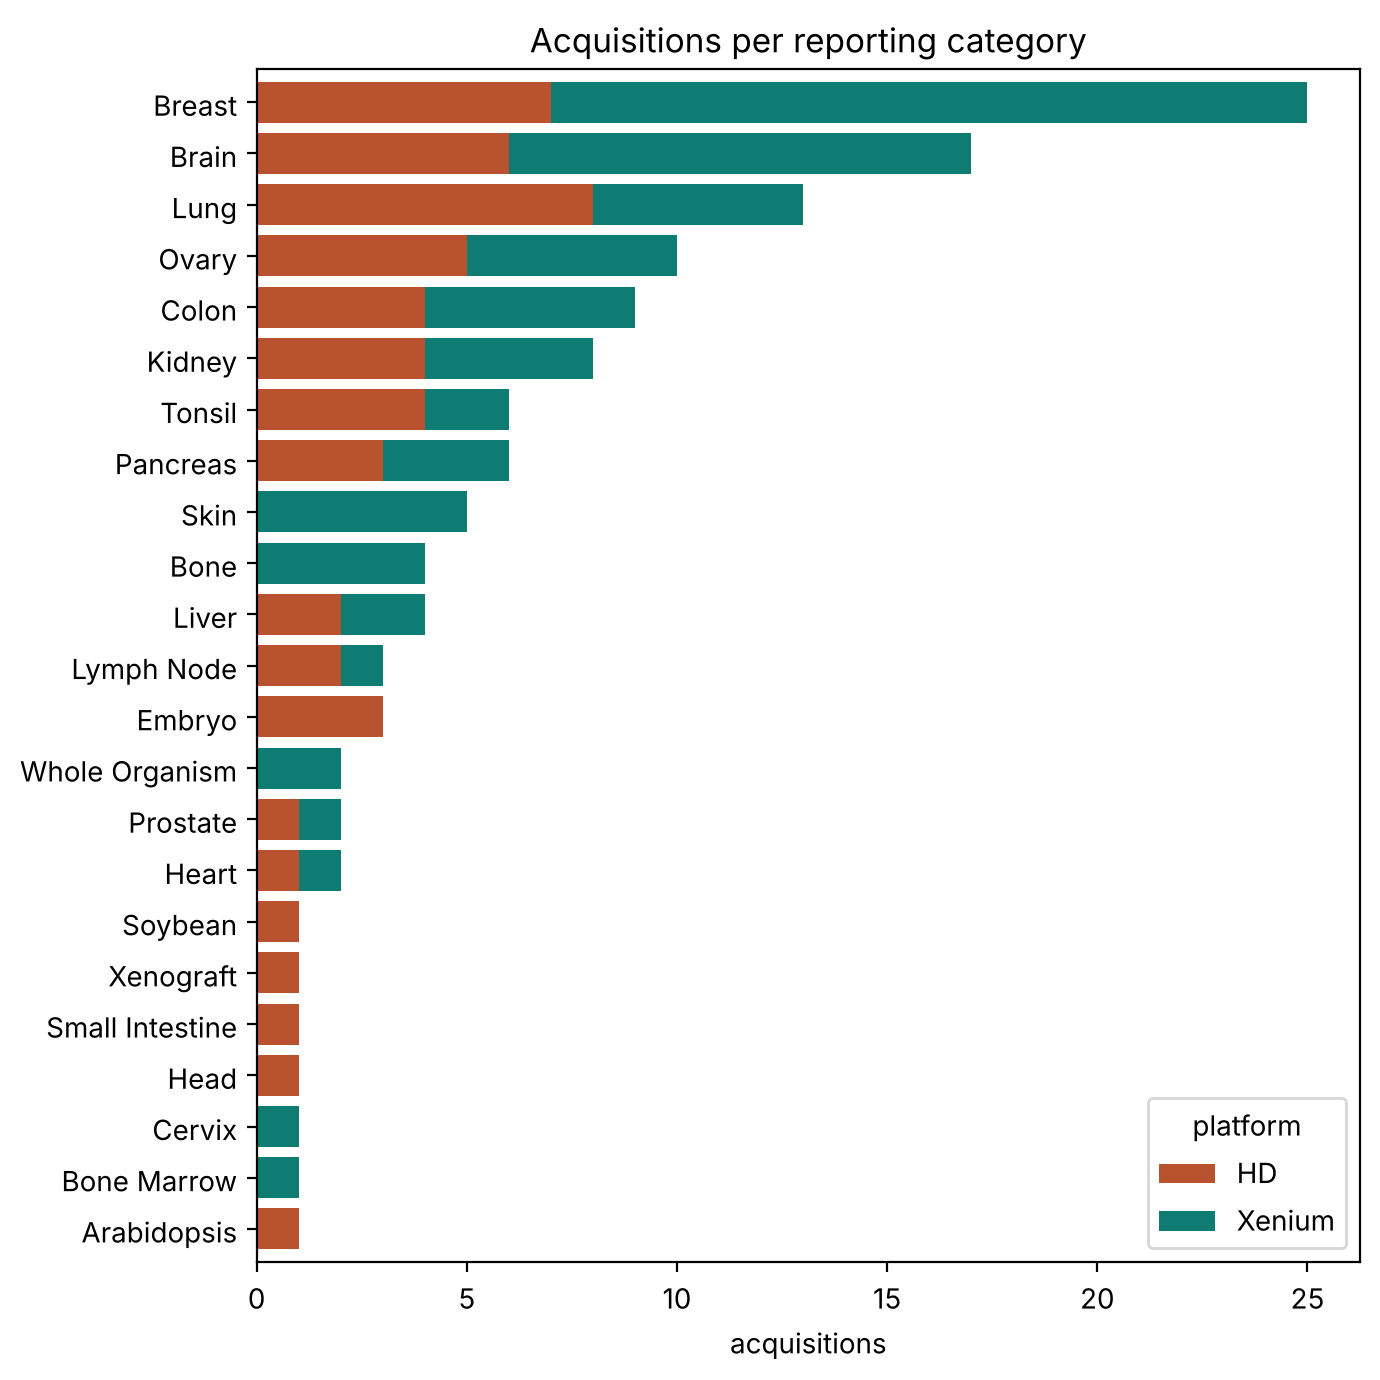

In [2]:
by = (cat.explode("categories")
         .groupby(["categories", "platform"]).size().unstack(fill_value=0))
by = by.loc[by.sum(axis=1).sort_values().index]
ax = by.plot.barh(stacked=True, figsize=(7, 7), color={"HD": "#b9532f", "Xenium": "#0e7c72"}, width=0.8)
ax.set_xlabel("acquisitions"); ax.set_ylabel(""); ax.set_title("Acquisitions per reporting category")
plt.tight_layout(); plt.show()

In [3]:
cat.groupby(["species_norm", "platform"]).size().unstack(fill_value=0)

platform,HD,Xenium
species_norm,,
Arabidopsis thaliana,1,0
Human,33,57
Mouse,13,14
Mouse; Human,1,0
Rattus norvegicus,1,0
Rhesus macaque,2,0
Soybean,1,0
Zebrafish (Danio rerio),1,0


Categories are reporting labels: `Embryo`, `Whole Organism`, `Xenograft`, `Arabidopsis` and
`Soybean` are not anatomical organs, and an acquisition can carry more than one label
(for example a mixed tissue array).

## 2. Where context is reported

Each context field has a status column. "Not reported" is not the same as "healthy".

In [4]:
fields = ["sample_condition", "sex", "age_value", "study_id", "donor_id_public"]
coverage = pd.DataFrame({f: cat[f].notna().groupby(cat["platform"]).mean() for f in fields}).T
(coverage * 100).round(0).astype(int).astype(str) + "%"

platform,HD,Xenium
sample_condition,98%,94%
sex,58%,14%
age_value,47%,13%
study_id,2%,17%
donor_id_public,2%,0%


In [5]:
cat["sample_condition"].value_counts()

sample_condition
neoplastic_tissue                     67
non_diseased_or_normal                39
reactive_or_hyperplastic               7
neurodegenerative_disease_or_model     3
not_applicable                         2
mixed_neoplastic_tissue_array          1
Name: count, dtype: int64

## 3. Find a question you can test

Example: human breast cancer on Xenium, the largest homogeneous group.

In [6]:
q = cat[(cat.platform == "Xenium") & (cat.species_norm == "Human") &
        cat.categories.apply(lambda c: "Breast" in c) &
        (cat.sample_condition == "neoplastic_tissue")]
q[["sample_id", "assay", "tissue", "sample_diagnosis", "sex", "age_text",
   "gene_positive_observations", "n_genes"]].sort_values("sample_id").head(12)

,sample_id,assay,tissue,sample_diagnosis,sex,age_text,gene_positive_observations,n_genes
56,HBCA041,NaN,Breast,Infiltrating ductal carcinoma; ductal carcinom...,NaN,NaN,574426,380
58,HBCH024,NaN,Tissue,Breast cancer,NaN,NaN,683798,5101
59,HBES040,NaN,Breast,Infiltrating ductal carcinoma,NaN,NaN,889765,280
82,XE-001,NaN,Breast,DCIS,NaN,NaN,254353,280
83,XE-002,NaN,Breast,DCIS,NaN,NaN,371534,280
84,XE-003,NaN,Breast,IDC,NaN,NaN,208245,280
85,XE-004,NaN,Breast,DCIS,NaN,NaN,356771,280
86,XE-005,NaN,Breast,DCIS,NaN,NaN,378819,280
88,XE-007,NaN,Breast,DCIS,NaN,NaN,150072,280
89,XE-008,NaN,Breast,DCIS,NaN,NaN,373091,280


Panels differ between acquisitions. Two samples share a measured gene axis only if they share a
`gene_table_id`; otherwise compare on the intersection of measured genes, never a zero-filled union.

In [7]:
print(f"{len(q)} acquisitions use {q.gene_table_id.nunique()} distinct measured gene axes")
q["n_genes"].describe()[["min", "50%", "max"]]

17 acquisitions use 17 distinct measured gene axes


min     280.0
50%     280.0
max    5101.0
Name: n_genes, dtype: float64

## 4. Context-matched vs context-shifted pairs

With age reported, you can hold the category and species fixed and vary only the age gap between
training and test acquisitions. Here: every ordered pair of acquisitions with reported age,
within one category, species and platform.

In [8]:
aged = cat[cat.age_value.notna()].explode("categories")
aged = aged[aged.age_unit.notna()]
pairs = (aged.merge(aged, on=["categories", "species_norm", "platform", "age_unit"], suffixes=("_train", "_test"))
             .query("sample_id_train != sample_id_test"))
pairs["age_gap"] = (pairs.age_value_test - pairs.age_value_train).abs()
pairs["design"] = pd.cut(pairs.age_gap, [-0.1, 5, 1e9], labels=["matched (≤5)", "shifted (>5)"])
summary = pairs.groupby(["categories", "species_norm", "platform", "design"], observed=True).size().unstack(fill_value=0)
summary[summary.sum(axis=1) > 0]

design                            matched (≤5)  shifted (>5)
categories species_norm platform                            
Brain      Mouse        HD                  20             0
                        Xenium              12             0
Breast     Human        HD                   0             2
Embryo     Mouse        HD                   6             0
Kidney     Mouse        HD                   2             0
Lung       Human        HD                   0             2
Ovary      Human        HD                   2             4
                        Xenium               2             0
Tonsil     Human        HD                   2             0

Human ovary on Visium HD has both matched and shifted pairs. Inspect the stratum before using it:
related material (the same source tissue imaged twice) would make a "shifted" pair look easier
than it is, so check `source_material_group_id` too.

In [9]:
cols = ["sample_id", "assay", "tissue", "sex", "age_text", "age_value", "age_unit",
        "sample_condition", "source_material_group_id"]
aged[(aged.categories == "Ovary") & (aged.species_norm == "Human") & (aged.platform == "HD")][cols]

,sample_id,assay,tissue,sex,age_text,age_value,age_unit,sample_condition,source_material_group_id
4,HD-005,HD-WT,Ovary,female,65 years,65.0,year,neoplastic_tissue,SMG-OVARY-ADJACENT-2025
33,HD-034,HD-3prime,Ovary,female,39 years,39.0,year,neoplastic_tissue,NaN
44,HD-045,HD-3prime,Ovary,female,65 years,65.0,year,neoplastic_tissue,SMG-OVARY-ADJACENT-2025


In [10]:
ov = pairs[(pairs.categories == "Ovary") & (pairs.species_norm == "Human") & (pairs.platform == "HD")]
ov[["sample_id_train", "age_value_train", "sample_id_test", "age_value_test", "age_gap", "design"]].sort_values("age_gap")

,sample_id_train,age_value_train,sample_id_test,age_value_test,age_gap,design
10,HD-005,65.0,HD-045,65.0,0.0,matched (≤5)
57,HD-045,65.0,HD-005,65.0,0.0,matched (≤5)
49,HD-034,39.0,HD-005,65.0,26.0,shifted (>5)
9,HD-005,65.0,HD-034,39.0,26.0,shifted (>5)
51,HD-034,39.0,HD-045,65.0,26.0,shifted (>5)
58,HD-045,65.0,HD-034,39.0,26.0,shifted (>5)


> **Read the table above before trusting the comparison.** HD-005 and HD-045 both belong to `SMG-OVARY-ADJACENT-2025`: the only *matched* pair is adjacent material from the same source. A score on that pair would overstate how well a model transfers to a new donor of the same age. Here, the honest design compares a 65-year-old training sample against HD-034 (39 years), and treats HD-005 ↔ HD-045 as a same-source reference, not a matched donor.

## 5. Cross-acquisition splits that respect related material

Acquisitions are **not** independent donors. Five known material groups span 16 acquisitions.
Group by `source_material_group_id` (falling back to the acquisition) so that related acquisitions
never sit on both sides of a split.

In [11]:
cat["group"] = cat["source_material_group_id"].fillna(cat["sample_id"])
print(cat[cat.source_material_group_id.notna()].groupby("source_material_group_id")["sample_id"].apply(list))

source_material_group_id
SMG-BREAST-IDC-LARGE                                          [HBES040, XE-031]
SMG-BREAST-ILC-PANELS                                          [XE-033, XE-034]
SMG-LUNG-POSTXENIUM-2024      [HD-010, HD-013, HD-014, HD-031, XE-017, XTNL005]
SMG-MOUSE-BRAIN-REPLICATES                                     [XE-043, XE-044]
SMG-OVARY-ADJACENT-2025                        [HD-005, HD-045, XE-019, XE-053]
Name: sample_id, dtype: object


In [12]:
def leave_one_group_out(df, category, species, platform):
    s = df[df.categories.apply(lambda c: category in c) & (df.species_norm == species) & (df.platform == platform)]
    for g in sorted(s.group.unique()):
        yield sorted(s[s.group != g].sample_id), sorted(s[s.group == g].sample_id)

for train, test in leave_one_group_out(cat, "Lung", "Human", "HD"):
    print("test", test, "← train", train)

test ['HD-028'] ← train ['HD-010', 'HD-013', 'HD-014', 'HD-031', 'HD-042', 'HD-052']
test ['HD-042'] ← train ['HD-010', 'HD-013', 'HD-014', 'HD-028', 'HD-031', 'HD-052']
test ['HD-052'] ← train ['HD-010', 'HD-013', 'HD-014', 'HD-028', 'HD-031', 'HD-042']
test ['HD-010', 'HD-013', 'HD-014', 'HD-031'] ← train ['HD-028', 'HD-042', 'HD-052']


Download only what the split needs (see [Download](../dataset/download.md)), then follow
[Tutorial 3](03_histology_crops.ipynb) to build image–expression pairs for each side.